# 01 · EDA de la OBT — PSet #3

**Problema:** clasificación binaria del abandono de clientes de telecomunicaciones.  
**Fuente:** `PSET2_CHURN.OBT.CUSTOMER_CHURN_OBT` (Snowflake).  
**Grano:** una fila por cliente. `INGESTED_AT` es auditoría, no fecha de abandono.  

El notebook utiliza datos **reales** de Snowflake; no incluye resultados predeterminados. Ejecutar con **Restart Kernel and Run All**.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import zscore
from src.datos import ORIGEN, leer_obt, hash_snapshot, variables_modelo

OUT = Path('/workspace/docs')
OUT.mkdir(parents=True, exist_ok=True)
df = leer_obt()
print(f"Origen: {ORIGEN}")
print(f"Tamaño: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"Hash SHA256 del contenido (sin INGESTED_AT): {hash_snapshot(df)}")
assert df['CUSTOMER_ID'].is_unique, 'La OBT debe tener una fila por cliente'
assert df['CHURN_FLAG'].notna().all(), 'El target no debe tener nulos'
display(df.head())

Origen: PSET2_CHURN.OBT.CUSTOMER_CHURN_OBT
Tamaño: 7,043 filas x 24 columnas
Hash SHA256 del contenido (sin INGESTED_AT): d394e39192c935f813db937647ea608341131d5b3021696fbbb186daff7043d3


,CUSTOMER_ID,GENDER,SENIOR_CITIZEN,PARTNER,DEPENDENTS,CONTRACT,PAPERLESS_BILLING,PAYMENT_METHOD,PHONE_SERVICE,MULTIPLE_LINES,...,TECH_SUPPORT,STREAMING_TV,STREAMING_MOVIES,TENURE_MONTHS,MONTHLY_CHARGES,TOTAL_CHARGES,TOTAL_CHARGES_MISSING,NEW_CUSTOMER_WITHOUT_CHARGES,CHURN_FLAG,INGESTED_AT
0,7590-VHVEG,Female,0,Yes,No,Month-to-month,Yes,Electronic check,No,No phone service,...,No,No,No,1,29.85,29.85,False,False,0,2026-11-16 05:14:12.210
1,5575-GNVDE,Male,0,No,No,One year,No,Mailed check,Yes,No,...,No,No,No,34,56.95,1889.50,False,False,0,2026-11-16 05:14:12.210
2,3668-QPYBK,Male,0,No,No,Month-to-month,Yes,Mailed check,Yes,No,...,No,No,No,2,53.85,108.15,False,False,1,2026-11-16 05:14:12.210
3,7795-CFOCW,Male,0,No,No,One year,No,Bank transfer (automatic),No,No phone service,...,Yes,No,No,45,42.30,1840.75,False,False,0,2026-11-16 05:14:12.210
4,9237-HQITU,Female,0,No,No,Month-to-month,Yes,Electronic check,Yes,No,...,No,No,No,2,70.70,151.65,False,False,1,2026-11-16 05:14:12.210


## 1. Tipos de variables y completitud

Diferenciamos valores `NULL` reales de cadenas vacías. No imputamos aquí; eso se hará dentro del Pipeline después de separar entrenamiento y prueba.

,columna,tipo
0,CUSTOMER_ID,object
1,GENDER,object
2,SENIOR_CITIZEN,int64
3,PARTNER,object
4,DEPENDENTS,object
5,CONTRACT,object
6,PAPERLESS_BILLING,object
7,PAYMENT_METHOD,object
8,PHONE_SERVICE,object
9,MULTIPLE_LINES,object


,columna,nulos,vacios_texto,pct_nulos_o_vacios
19,TOTAL_CHARGES,11,0,0.156183
0,CUSTOMER_ID,0,0,0.000000
2,SENIOR_CITIZEN,0,0,0.000000
1,GENDER,0,0,0.000000
4,DEPENDENTS,0,0,0.000000
5,CONTRACT,0,0,0.000000
6,PAPERLESS_BILLING,0,0,0.000000
3,PARTNER,0,0,0.000000
7,PAYMENT_METHOD,0,0,0.000000
8,PHONE_SERVICE,0,0,0.000000


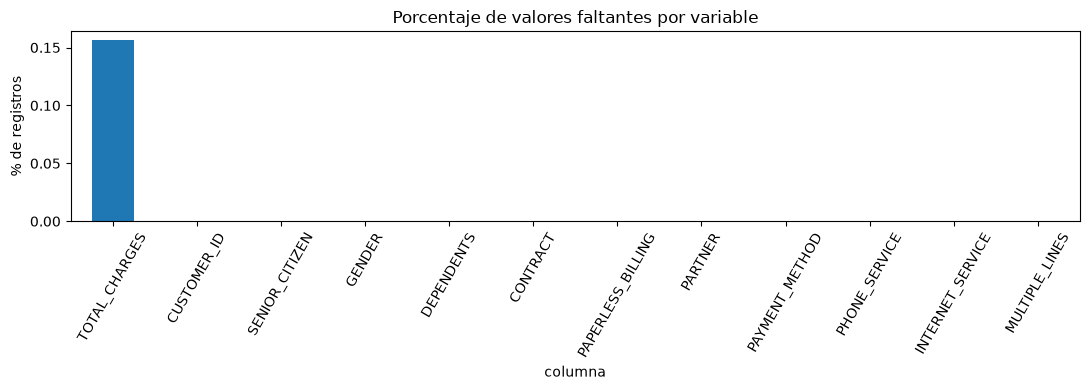

In [2]:
tipos = pd.DataFrame({'columna':df.columns,'tipo':df.dtypes.astype(str).values})
display(tipos)

def vacios_en(col):
    serie = df[col]
    if pd.api.types.is_object_dtype(serie) or pd.api.types.is_string_dtype(serie):
        return int((serie.astype('string').str.strip() == '').fillna(False).sum())
    return 0

faltantes = pd.DataFrame({
    'columna': df.columns,
    'nulos': [int(df[c].isna().sum()) for c in df.columns],
    'vacios_texto': [vacios_en(c) for c in df.columns]
})
faltantes['pct_nulos_o_vacios'] = (faltantes.nulos + faltantes.vacios_texto) * 100 / len(df)
display(faltantes.sort_values('pct_nulos_o_vacios',ascending=False))
ax = faltantes.sort_values('pct_nulos_o_vacios',ascending=False).head(12).plot.bar(
    x='columna', y='pct_nulos_o_vacios', legend=False, figsize=(11,4), rot=60)
ax.set_ylabel('% de registros')
ax.set_title('Porcentaje de valores faltantes por variable')
plt.tight_layout()
plt.savefig(OUT/'eda_faltantes.png',dpi=140)
plt.show()

## 2. Estadística descriptiva y target

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
CUSTOMER_ID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GENDER,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SENIOR_CITIZEN,7043.0,NaN,NaN,NaN,0.162147,0.0,0.0,0.0,0.0,1.0,0.368612
PARTNER,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DEPENDENTS,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CONTRACT,7043,3,Month-to-month,3875,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PAPERLESS_BILLING,7043,2,Yes,4171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PAYMENT_METHOD,7043,4,Electronic check,2365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PHONE_SERVICE,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MULTIPLE_LINES,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Target (0=permanece, 1=abandona):


,clientes
CHURN_FLAG,
0,5174
1,1869


Tasa observada de abandono: 26.54%
Razón de clases positivas/negativas: 1869/5174


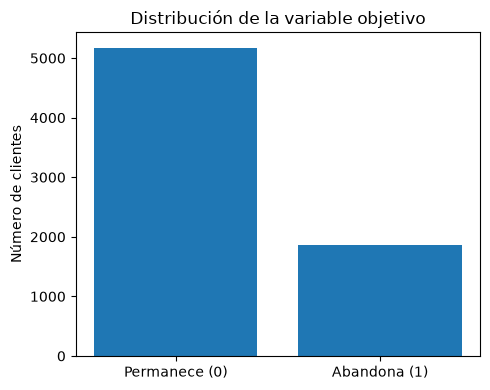

In [3]:
display(df.describe(include='all').T)
target_counts = df['CHURN_FLAG'].astype(int).value_counts().sort_index()
tasa = float(target_counts.get(1, 0) / target_counts.sum())
print('Target (0=permanece, 1=abandona):')
display(target_counts.rename('clientes').to_frame())
print(f'Tasa observada de abandono: {100*tasa:.2f}%')
print(f'Razón de clases positivas/negativas: {target_counts.get(1,0)}/{target_counts.get(0,0)}')
fig, ax = plt.subplots(figsize=(5,4))
ax.bar(['Permanece (0)','Abandona (1)'],[target_counts.get(0,0),target_counts.get(1,0)])
ax.set_ylabel('Número de clientes')
ax.set_title('Distribución de la variable objetivo')
plt.tight_layout()
plt.savefig(OUT/'eda_target.png',dpi=140)
plt.show()

## 3. Detección de atípicos: IQR y Z-score ≥ 3

Las variables binarias y los identificadores no se utilizan para detectar outliers. IQR y Z-score reflejan reglas estadísticas, no necesariamente errores del negocio.

,variable,validos,iqr_atipicos,zscore_3_atipicos
0,TENURE_MONTHS,7043,0,0
1,MONTHLY_CHARGES,7043,0,0
2,TOTAL_CHARGES,7032,0,0


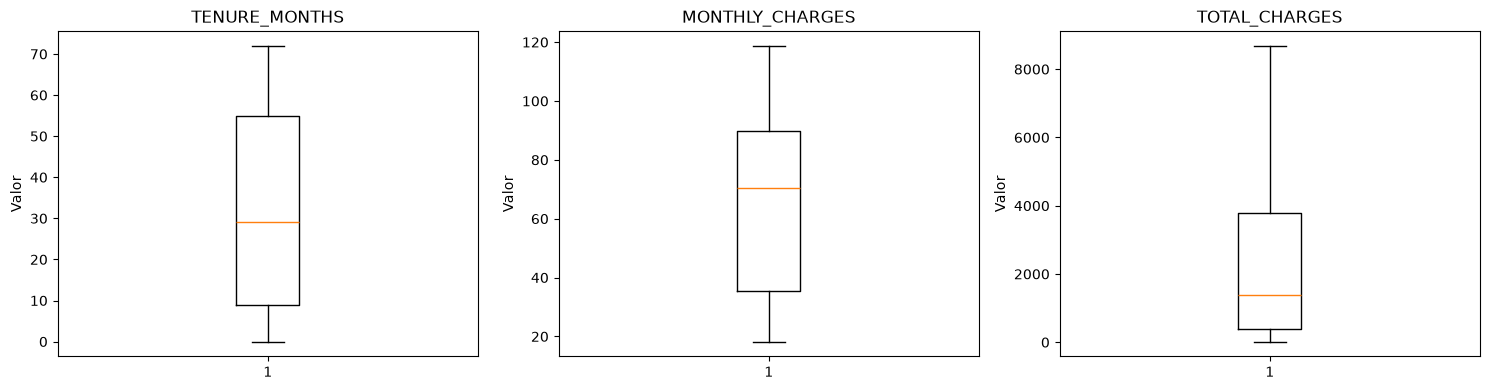

In [4]:
numericas = [c for c in ['TENURE_MONTHS','MONTHLY_CHARGES','TOTAL_CHARGES'] if c in df.columns]
resultado_outliers=[]
for col in numericas:
    x = pd.to_numeric(df[col], errors='coerce').dropna().astype(float)
    q1,q3=x.quantile([0.25,0.75]); iqr=q3-q1
    iqr_out=int(((x < q1-1.5*iqr)|(x > q3+1.5*iqr)).sum())
    if x.std(ddof=0)>0:
        z_out=int((np.abs(zscore(x.to_numpy(),nan_policy='omit'))>=3).sum())
    else:
        z_out=0
    resultado_outliers.append({'variable':col,'validos':len(x),'iqr_atipicos':iqr_out,'zscore_3_atipicos':z_out})
display(pd.DataFrame(resultado_outliers))
if numericas:
    fig, axes = plt.subplots(1,len(numericas),figsize=(5*len(numericas),4),squeeze=False)
    for ax,col in zip(axes.ravel(),numericas):
        ax.boxplot(pd.to_numeric(df[col],errors='coerce').dropna().to_numpy())
        ax.set_title(col)
        ax.set_ylabel('Valor')
    plt.tight_layout()
    plt.savefig(OUT/'eda_boxplots.png',dpi=140)
    plt.show()

## 4. Correlación numérica con el target

Usaremos **Spearman** como exploración de relaciones monotónicas con el target binario, sin asumir normalidad de los importes. Esta correlación no implica causalidad. Para variables categóricas se compararán tasas por grupo.

,TENURE_MONTHS,MONTHLY_CHARGES,TOTAL_CHARGES,TOTAL_CHARGES_MISSING,NEW_CUSTOMER_WITHOUT_CHARGES,CHURN_FLAG
TENURE_MONTHS,1.000000,0.276417,0.889177,-0.068432,-0.068432,-0.367062
MONTHLY_CHARGES,0.276417,1.000000,0.638032,-0.029861,-0.029861,0.184743
TOTAL_CHARGES,0.889177,0.638032,1.000000,NaN,NaN,-0.232190
TOTAL_CHARGES_MISSING,-0.068432,-0.029861,NaN,1.000000,1.000000,-0.023771
NEW_CUSTOMER_WITHOUT_CHARGES,-0.068432,-0.029861,NaN,1.000000,1.000000,-0.023771
CHURN_FLAG,-0.367062,0.184743,-0.232190,-0.023771,-0.023771,1.000000


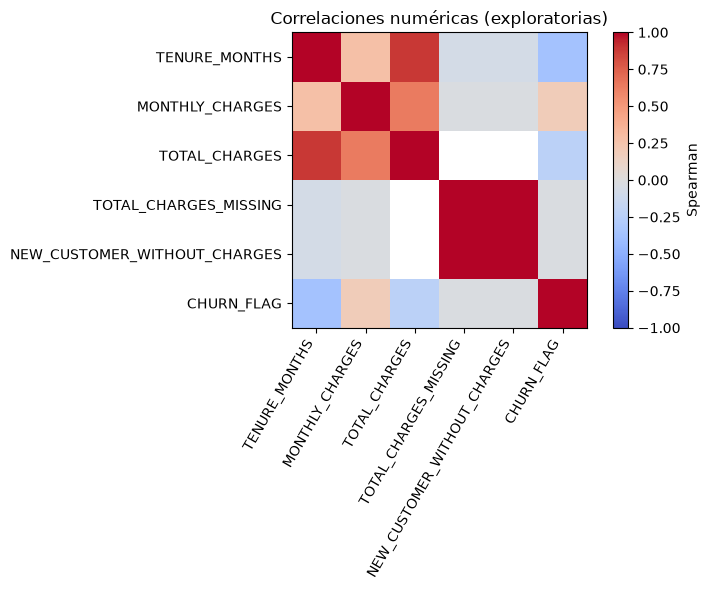

In [5]:
cols_corr = [c for c in ['TENURE_MONTHS','MONTHLY_CHARGES','TOTAL_CHARGES',
                          'TOTAL_CHARGES_MISSING','NEW_CUSTOMER_WITHOUT_CHARGES','CHURN_FLAG'] if c in df]
mat = df[cols_corr].apply(pd.to_numeric,errors='coerce').corr(method='spearman')
display(mat)
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(mat, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(cols_corr)),cols_corr,rotation=60,ha='right')
ax.set_yticks(range(len(cols_corr)),cols_corr)
fig.colorbar(im,ax=ax,label='Spearman')
ax.set_title('Correlaciones numéricas (exploratorias)')
plt.tight_layout()
plt.savefig(OUT/'eda_correlacion.png',dpi=140)
plt.show()

## 5. Contrato y abandono (comparación de grupos)

,clientes,abandonos,tasa_abandono,tasa_abandono_pct
CONTRACT,,,,
Month-to-month,3875,1655,0.427097,42.709677
One year,1473,166,0.112695,11.269518
Two year,1695,48,0.028319,2.831858


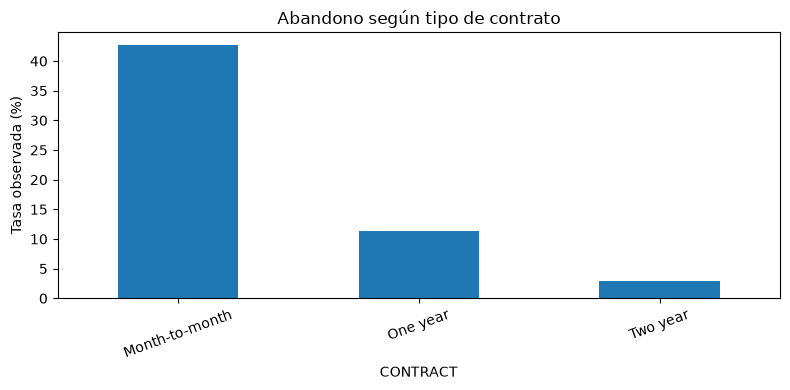

In [6]:
tabla_contrato = (df.groupby('CONTRACT')['CHURN_FLAG']
  .agg(clientes='size', abandonos='sum', tasa_abandono='mean')
  .sort_values('tasa_abandono', ascending=False))
tabla_contrato['tasa_abandono_pct']=100*tabla_contrato['tasa_abandono']
display(tabla_contrato)
ax=tabla_contrato['tasa_abandono_pct'].plot.bar(figsize=(8,4),rot=20)
ax.set_title('Abandono según tipo de contrato')
ax.set_ylabel('Tasa observada (%)')
plt.tight_layout()
plt.savefig(OUT/'eda_contrato.png',dpi=140)
plt.show()

## 6. Hallazgos y consecuencias en el modelado

Estos tres hallazgos se calculan de la OBT; comprobar su interpretación antes de incluirlos en el memo. El estudio es **descriptivo y no causal**.

In [7]:
contrato_mes = float(tabla_contrato.loc['Month-to-month','tasa_abandono_pct']) if 'Month-to-month' in tabla_contrato.index else None
n_nulos = int(df['TOTAL_CHARGES'].isna().sum())
resumen = {
    'source': ORIGEN,
    'filas': int(len(df)),
    'columnas': int(len(df.columns)),
    'clientes_unicos': int(df['CUSTOMER_ID'].nunique()),
    'abandonos': int(target_counts.get(1,0)),
    'tasa_abandono_pct': round(tasa*100,3),
    'total_charges_nulos': n_nulos,
    'contrato_mensual_tasa_pct': round(contrato_mes,3) if contrato_mes is not None else None,
    'sha256_dataset': hash_snapshot(df),
}
(OUT/'eda_resumen.json').write_text(json.dumps(resumen,indent=2,ensure_ascii=False),encoding='utf-8')
display(pd.DataFrame([
  {'Hallazgo':f'Target: {100*tasa:.2f}% de abandono',
   'Evidencia':f'{target_counts.get(1,0)} de {len(df)}',
   'Consecuencia':'Validación estratificada; PR-AUC además de recall y precisión'},
  {'Hallazgo':'Diferencias de abandono por tipo de contrato',
   'Evidencia': f'Contrato mensual: {contrato_mes:.2f}%' if contrato_mes is not None else 'Revisar tabla de contratos',
   'Consecuencia':'Explorar interacción CONTRATO × TENURE en una feature derivada'},
  {'Hallazgo':'TOTAL_CHARGES contiene valores ausentes',
   'Evidencia':f'{n_nulos} de {len(df)}',
   'Consecuencia':'Imputación únicamente dentro del pipeline y análisis del indicador de ausencia'},
]))
print('Evidencias guardadas en docs/ (PNG y eda_resumen.json)')

,Hallazgo,Evidencia,Consecuencia
0,Target: 26.54% de abandono,1869 de 7043,Validación estratificada; PR-AUC además de rec...
1,Diferencias de abandono por tipo de contrato,Contrato mensual: 42.71%,Explorar interacción CONTRATO × TENURE en una ...
2,TOTAL_CHARGES contiene valores ausentes,11 de 7043,Imputación únicamente dentro del pipeline y an...


Evidencias guardadas en docs/ (PNG y eda_resumen.json)


## 7. Vista previa de features derivadas (sin ajustar aún modelos)

`MONTHLY_NEW_CUSTOMER` se motiva por la relación entre contrato y abandono. `SERVICE_BUNDLE_COUNT` resume servicios actuales del cliente. Las dos se calculan con información existente en el mismo snapshot de entrada; en el siguiente paso confirmaremos la disponibilidad operativa antes de inferir y las incorporaremos al Pipeline.

In [8]:
from src.pipeline import FeaturesDerivadas
X,y=variables_modelo(df)
X_demo=FeaturesDerivadas().transform(X)
display(X_demo[['MONTHLY_NEW_CUSTOMER','SERVICE_BUNDLE_COUNT']].describe())
print('Columnas del modelo:', X_demo.shape[1])
print('Target por separado:', y.name)
print('Comprobacion: ni CUSTOMER_ID, ni INGESTED_AT, ni CHURN_FLAG están en X:',
      not any(c in X_demo.columns for c in ['CUSTOMER_ID','INGESTED_AT','CHURN_FLAG']))

,MONTHLY_NEW_CUSTOMER,SERVICE_BUNDLE_COUNT
count,7043.000000,7043.000000
mean,0.283118,2.037910
std,0.450545,1.847682
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,2.000000
75%,1.000000,3.000000
max,1.000000,6.000000


Columnas del modelo: 23
Target por separado: CHURN_FLAG
Comprobacion: ni CUSTOMER_ID, ni INGESTED_AT, ni CHURN_FLAG están en X: True
